In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
import re
import html
from collections import Counter
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score


print("Docker Notebook is working!")

Docker Notebook is working!


In [2]:
df = pd.read_csv("../data/Tweets.csv")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


# Member 2: Data Understanding, Cleaning and Sampling

This section explores the Twitter US Airline Sentiment dataset,
checks missing values and duplicates, applies transformations,
and compares different sampling techniques.

In [3]:
# Display the first five rows
print("First 5 rows:")
display(df.head())

# Dataset dimensions
print("\nDataset shape:")
print(df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types
print("\nData types:")
print(df.dtypes)

# Dataset information
print("\nDataset information:")
df.info()

# Descriptive statistics for numerical columns
print("\nNumerical descriptive statistics:")
display(df.describe())

# Descriptive statistics for all columns
print("\nDescriptive statistics for all columns:")
display(df.describe(include="all").T)

# Identify important columns
print("\nText column: text")
print("Target label: airline_sentiment")
print("Category column: airline")

First 5 rows:


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)



Dataset shape:
(14640, 15)

Column names:
['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']

Data types:
tweet_id                          int64
airline_sentiment                   str
airline_sentiment_confidence    float64
negativereason                      str
negativereason_confidence       float64
airline                             str
airline_sentiment_gold              str
name                                str
negativereason_gold                 str
retweet_count                     int64
text                                str
tweet_coord                         str
tweet_created                       str
tweet_location                      str
user_timezone                       str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeInd

,tweet_id,airline_sentiment_confidence,negativereason_confidence,retweet_count
count,1.464000e+04,14640.000000,10522.000000,14640.000000
mean,5.692184e+17,0.900169,0.638298,0.082650
std,7.791112e+14,0.162830,0.330440,0.745778
min,5.675883e+17,0.335000,0.000000,0.000000
25%,5.685592e+17,0.692300,0.360600,0.000000
50%,5.694779e+17,1.000000,0.670600,0.000000
75%,5.698905e+17,1.000000,1.000000,0.000000
max,5.703106e+17,1.000000,1.000000,44.000000



Descriptive statistics for all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tweet_id,14640.0,NaN,NaN,NaN,569218351767499200.0,779111158481836.75,567588278875213824.0,568559178101439488.0,569477857923110912.0,569890473289000960.0,570310600460525568.0
airline_sentiment,14640,3,negative,9178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airline_sentiment_confidence,14640.0,NaN,NaN,NaN,0.900169,0.16283,0.335,0.6923,1.0,1.0,1.0
negativereason,9178,10,Customer Service Issue,2910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
negativereason_confidence,10522.0,NaN,NaN,NaN,0.638298,0.33044,0.0,0.3606,0.6706,1.0,1.0
airline,14640,6,United,3822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airline_sentiment_gold,40,3,negative,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,14640,7701,JetBlueNews,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
negativereason_gold,32,13,Customer Service Issue,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retweet_count,14640.0,NaN,NaN,NaN,0.08265,0.745778,0.0,0.0,0.0,0.0,44.0



Text column: text
Target label: airline_sentiment
Category column: airline


## 2.2 Missing Values and Duplicate Records

This section checks missing values and duplicate records.
Missing tweet text is replaced with an empty string because
the text may still be useful for the remaining dataset analysis.
Duplicate records are handled to avoid counting the same tweet
more than once.

In [4]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Create output folders
os.makedirs("../output", exist_ok=True)
os.makedirs("../output/figures", exist_ok=True)

# Shape before cleaning
shape_before = df_clean.shape

print("Shape before cleaning:", shape_before)

# Missing values before cleaning
print("\nMissing values per column:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

# Duplicate rows before cleaning
print("\nExact duplicate rows:", df_clean.duplicated().sum())

# Duplicate tweet IDs, if the column exists
if "tweet_id" in df_clean.columns:
    print(
        "Duplicate tweet IDs:",
        df_clean["tweet_id"].duplicated().sum()
    )

# Handle missing tweet text
if "text" in df_clean.columns:
    df_clean["text"] = df_clean["text"].fillna("")

# Remove duplicate tweets using tweet_id
if "tweet_id" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(
        subset="tweet_id",
        keep="first"
    )
else:
    # Fallback if tweet_id is unavailable
    df_clean = df_clean.drop_duplicates(keep="first")

# Reset row indices
df_clean = df_clean.reset_index(drop=True)

# Shape after cleaning
shape_after = df_clean.shape

print("\nShape after cleaning:", shape_after)
print("Number of rows removed:", shape_before[0] - shape_after[0])

print("\nRemaining missing values:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

print("\nFinal duplicate tweet IDs:")
if "tweet_id" in df_clean.columns:
    print(df_clean["tweet_id"].duplicated().sum())

Shape before cleaning: (14640, 15)

Missing values per column:


,Missing Values
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5462
negativereason_confidence,4118
airline,0
airline_sentiment_gold,14600
name,0
negativereason_gold,14608
retweet_count,0



Exact duplicate rows: 36
Duplicate tweet IDs: 155

Shape after cleaning: (14485, 15)
Number of rows removed: 155

Remaining missing values:


,Missing Values
tweet_id,0
airline_sentiment,0
airline_sentiment_confidence,0
negativereason,5403
negativereason_confidence,4069
airline,0
airline_sentiment_gold,14445
name,0
negativereason_gold,14453
retweet_count,0



Final duplicate tweet IDs:
0


## 2.3 Selecting Data with loc and iloc

In [5]:
# Example 1: loc
# Select negative tweets from the dataset

negative_tweets = df_clean.loc[
    df_clean["airline_sentiment"] == "negative",
    ["airline", "airline_sentiment", "text"]
]

print("First 5 negative tweets:")
display(negative_tweets.head())

# Example 2: iloc
# Select the first five rows and first four columns

print("\nFirst 5 rows and first 4 columns:")
display(df_clean.iloc[:5, :4])

# Example 3: iloc with np.r_
# Select rows 0-2 and 10-12, and the first four columns

selected_rows = df_clean.iloc[
    np.r_[0:3, 10:13],
    np.r_[0:4]
]

print("\nSelected rows using np.r_:")
display(selected_rows)

First 5 negative tweets:


,airline,airline_sentiment,text
3,Virgin America,negative,@VirginAmerica it's really aggressive to blast...
4,Virgin America,negative,@VirginAmerica and it's a really big bad thing...
5,Virgin America,negative,@VirginAmerica seriously would pay $30 a fligh...
15,Virgin America,negative,@VirginAmerica SFO-PDX schedule is still MIA.
17,Virgin America,negative,@VirginAmerica I flew from NYC to SFO last we...



First 5 rows and first 4 columns:


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason
0,570306133677760513,neutral,1.0000,NaN
1,570301130888122368,positive,0.3486,NaN
2,570301083672813571,neutral,0.6837,NaN
3,570301031407624196,negative,1.0000,Bad Flight
4,570300817074462722,negative,1.0000,Can't Tell



Selected rows using np.r_:


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason
0,570306133677760513,neutral,1.0000,NaN
1,570301130888122368,positive,0.3486,NaN
2,570301083672813571,neutral,0.6837,NaN
10,570294189143031808,neutral,0.6769,NaN
11,570289724453216256,positive,1.0000,NaN
12,570289584061480960,positive,1.0000,NaN


## 2.4 Data Transformations and Feature Creation

In [6]:
# Work on a copy
df_clean = df_clean.copy()

# Transformation 1: Encode sentiment labels
sentiment_mapping = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

df_clean["sentiment_encoded"] = (
    df_clean["airline_sentiment"]
    .map(sentiment_mapping)
)

# Transformation 2: Create tweet length feature
df_clean["tweet_length"] = df_clean["text"].str.len()

# Transformation 3: Convert tweet_created to datetime
if "tweet_created" in df_clean.columns:
    df_clean["tweet_created_parsed"] = pd.to_datetime(
        df_clean["tweet_created"],
        errors="coerce",
        utc=True
    )

# Show the transformed data
columns_to_show = [
    "airline",
    "airline_sentiment",
    "sentiment_encoded",
    "text",
    "tweet_length"
]

if "tweet_created_parsed" in df_clean.columns:
    columns_to_show.append("tweet_created_parsed")

print("Data after transformations:")
display(df_clean[columns_to_show].head())

print("\nEncoded sentiment distribution:")
display(
    df_clean["sentiment_encoded"]
    .value_counts(dropna=False)
    .sort_index()
)

Data after transformations:


,airline,airline_sentiment,sentiment_encoded,text,tweet_length,tweet_created_parsed
0,Virgin America,neutral,1,@VirginAmerica What @dhepburn said.,35,2015-02-24 19:35:52+00:00
1,Virgin America,positive,2,@VirginAmerica plus you've added commercials t...,72,2015-02-24 19:15:59+00:00
2,Virgin America,neutral,1,@VirginAmerica I didn't today... Must mean I n...,71,2015-02-24 19:15:48+00:00
3,Virgin America,negative,0,@VirginAmerica it's really aggressive to blast...,126,2015-02-24 19:15:36+00:00
4,Virgin America,negative,0,@VirginAmerica and it's a really big bad thing...,55,2015-02-24 19:14:45+00:00



Encoded sentiment distribution:


sentiment_encoded
0    9082
1    3069
2    2334
Name: count, dtype: int64

## 2.5 Sampling Techniques

Three sampling methods are compared:
simple random sampling, stratified sampling, and cluster sampling.

The sentiment distribution of each sample is compared with the
original dataset.

In [7]:
# Use a fixed random state for reproducibility
RANDOM_STATE = 42
SAMPLE_FRACTION = 0.20

# 1. Simple Random Sampling
random_sample = df_clean.sample(
    frac=SAMPLE_FRACTION,
    random_state=RANDOM_STATE
)

print("Random sample shape:", random_sample.shape)

# 2. Stratified Sampling
# Keep approximately the same sentiment proportions
stratified_sample, _ = train_test_split(
    df_clean,
    test_size=1 - SAMPLE_FRACTION,
    random_state=RANDOM_STATE,
    stratify=df_clean["airline_sentiment"]
)

print("Stratified sample shape:", stratified_sample.shape)

# 3. Cluster Sampling
# Select two airlines randomly, then take all tweets from them
airlines = df_clean["airline"].dropna().unique()

rng = np.random.default_rng(RANDOM_STATE)

selected_airlines = rng.choice(
    airlines,
    size=min(2, len(airlines)),
    replace=False
)

cluster_sample = df_clean[
    df_clean["airline"].isin(selected_airlines)
].copy()

print("Selected airline clusters:", selected_airlines)
print("Cluster sample shape:", cluster_sample.shape)

Random sample shape: (2897, 18)
Stratified sample shape: (2897, 18)
Selected airline clusters: ['Virgin America' 'US Airways']
Cluster sample shape: (3417, 18)


Sentiment distribution comparison (%):


,Original,Random,Stratified,Cluster
airline_sentiment,,,,
negative,62.70,64.55,62.69,71.52
neutral,21.19,20.88,21.19,16.15
positive,16.11,14.57,16.12,12.32


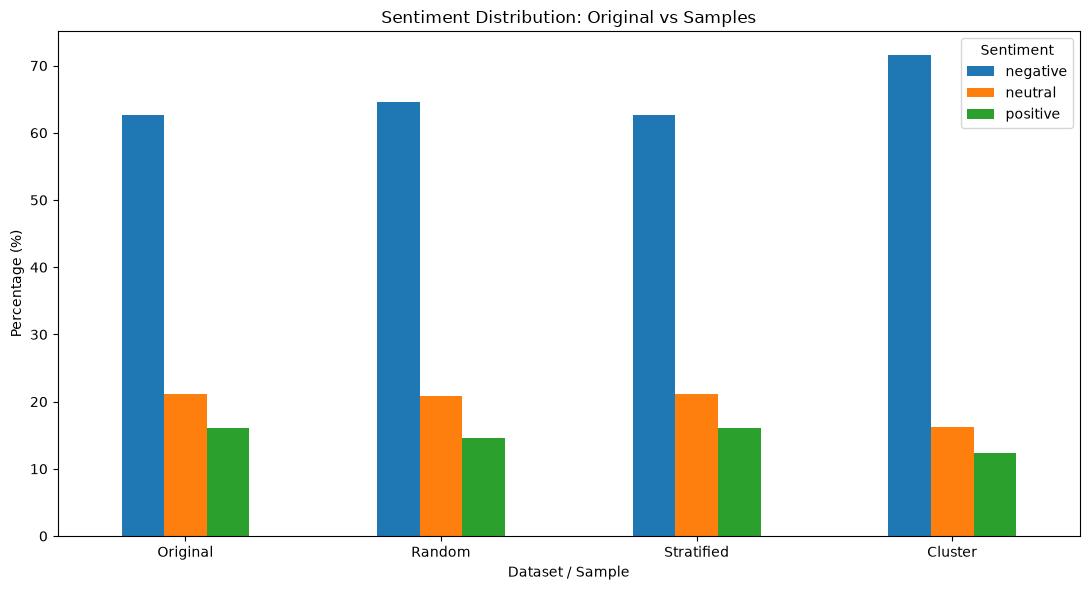

In [8]:
# Compare sentiment distributions

def sentiment_distribution(data, sample_name):
    proportions = (
        data["airline_sentiment"]
        .value_counts(normalize=True)
        .mul(100)
    )

    proportions.name = sample_name
    return proportions


distribution_comparison = pd.concat(
    [
        sentiment_distribution(df_clean, "Original"),
        sentiment_distribution(random_sample, "Random"),
        sentiment_distribution(stratified_sample, "Stratified"),
        sentiment_distribution(cluster_sample, "Cluster")
    ],
    axis=1
).fillna(0)

distribution_comparison = distribution_comparison.reindex(
    ["negative", "neutral", "positive"]
)

print("Sentiment distribution comparison (%):")
display(distribution_comparison.round(2))

# Visual comparison
ax = distribution_comparison.T.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Sentiment Distribution: Original vs Samples")
ax.set_xlabel("Dataset / Sample")
ax.set_ylabel("Percentage (%)")
ax.legend(title="Sentiment")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../output/figures/sampling_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [9]:
# 2.6 Save Cleaned Dataset

# Use the cleaned dataset for the following notebook sections
df = df_clean.copy()

output_path = "../output/cleaned_data.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully.")
print("File path:", output_path)
print("Final dataset shape:", df.shape)

print("\nSaved file exists:", os.path.exists(output_path))

Cleaned dataset saved successfully.
File path: ../output/cleaned_data.csv
Final dataset shape: (14485, 18)

Saved file exists: True


# Member 3: Text Features, Correlation and Text Analysis

This part cleans the tweet text, builds simple numeric text features, studies their correlations, and compares the words used in negative and positive tweets.

## 3.0 Setup


In [10]:
# reuse df from earlier sections if it exists, else load it
if "df" not in globals():
    df = pd.read_csv("../data/Tweets.csv")

tdf = df.copy()

print("Shape before removing duplicates:", tdf.shape)
# if an earlier section already removed duplicates, this changes nothing
tdf = tdf.drop_duplicates(subset="tweet_id").reset_index(drop=True)
print("Shape after removing duplicates: ", tdf.shape)

# output folders
os.makedirs("../output/figures", exist_ok=True)

Shape before removing duplicates: (14485, 18)
Shape after removing duplicates:  (14485, 18)


## 3.1 Cleaned text column


In [11]:
def clean_text(s):
    # missing -> empty string
    if pd.isna(s):
        return ""
    s = html.unescape(str(s)).lower()
    s = s.replace("’", "'")
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"@\w+", " ", s)
    s = s.replace("#", "")
    s = re.sub(r"\d+", " ", s)
    s = re.sub(r"[^a-z' ]", " ", s)
    words = [w.strip("'") for w in s.split()]
    return " ".join(w for w in words if w)


tdf["cleaned_text"] = tdf["text"].apply(clean_text)

# 8 examples: original vs cleaned
pd.set_option("display.max_colwidth", 120)
tdf[["text", "cleaned_text"]].sample(8, random_state=42)

,text,cleaned_text
8709,@JetBlue I understand but everyone said different things and there was a flight out Late Flightr that night but only...,i understand but everyone said different things and there was a flight out late flightr that night but only one of u...
6501,@SouthwestAir can you make a premium wifi that I can pay $30 for that is decent? #slow-fi,can you make a premium wifi that i can pay for that is decent slow fi
2366,@united No wonder the cabin is filthy. #badservice,no wonder the cabin is filthy badservice
6291,@SouthwestAir When does PV get approved? I am ready to go!!,when does pv get approved i am ready to go
169,@VirginAmerica to jump into the Dallas-Austin market - @Dallas_News http://t.co/EwwGi97gdx,to jump into the dallas austin market
2034,@united This has been the WORST flight experience I've ever had. Thank you for ending my vacation on such a bad note.,this has been the worst flight experience i've ever had thank you for ending my vacation on such a bad note
12867,@AmericanAir Least you could do would be to refund me the one-way ticket I had to buy since you weren't able to acco...,least you could do would be to refund me the one way ticket i had to buy since you weren't able to accommodate thank...
1944,@united apparently sleeping in B terminal wasn't the worst situation. Someone told other UA passengers they had to s...,apparently sleeping in b terminal wasn't the worst situation someone told other ua passengers they had to sleep at b...


In [12]:
n_empty = (tdf["cleaned_text"] == "").sum()
print("Records empty after cleaning:", n_empty, "out of", len(tdf))

Records empty after cleaning: 0 out of 14485


## 3.2 Numerical text features

New numeric columns for each tweet:


In [13]:
words = tdf["cleaned_text"].str.split()
orig = tdf["text"].fillna("")

tdf["char_count"] = orig.str.len()
tdf["word_count"] = words.str.len()
tdf["unique_word_count"] = words.apply(lambda w: len(set(w)))
tdf["avg_word_length"] = words.apply(lambda w: sum(len(x) for x in w) / len(w) if len(w) > 0 else 0)
tdf["stopword_count"] = words.apply(lambda w: sum(x in ENGLISH_STOP_WORDS for x in w))
tdf["mention_count"] = orig.str.count(r"@\w+")

num_cols = ["char_count", "word_count", "unique_word_count", "avg_word_length",
            "stopword_count", "mention_count", "retweet_count"]
tdf[num_cols].describe().round(2)

,char_count,word_count,unique_word_count,avg_word_length,stopword_count,mention_count,retweet_count
count,14485.00,14485.00,14485.00,14485.00,14485.00,14485.00,14485.00
mean,103.84,16.03,15.03,4.40,7.98,1.13,0.08
std,36.26,6.80,6.12,0.83,4.23,0.40,0.75
min,12.00,1.00,1.00,1.33,0.00,1.00,0.00
25%,77.00,11.00,10.00,3.90,5.00,1.00,0.00
50%,114.00,17.00,16.00,4.30,8.00,1.00,0.00
75%,136.00,22.00,20.00,4.78,11.00,1.00,0.00
max,186.00,31.00,30.00,25.00,22.00,6.00,44.00


In [14]:
# save cleaned data (used by Member 4)
save_cols = ["tweet_id", "airline", "airline_sentiment", "text", "cleaned_text"] + num_cols
tdf[save_cols].to_csv("../output/cleaned_text.csv", index=False)
print("Saved ../output/cleaned_text.csv", tdf[save_cols].shape)

Saved ../output/cleaned_text.csv (14485, 12)


## 3.3 Correlation analysis

The Pearson correlation coefficient `r` measures the linear relationship between two numeric variables (from -1 to +1). We compute it for all numeric features, draw a heatmap, and then rank the feature pairs by strength:

- strong: |r| >= 0.7
- moderate: 0.4 <= |r| < 0.7
- weak: |r| < 0.4

In [15]:
corr = tdf[num_cols].corr(method="pearson")
print(corr.round(2))

                   char_count  word_count  unique_word_count  avg_word_length  \
char_count               1.00        0.92               0.92             0.05   
word_count               0.92        1.00               0.99            -0.21   
unique_word_count        0.92        0.99               1.00            -0.18   
avg_word_length          0.05       -0.21              -0.18             1.00   
stopword_count           0.72        0.88               0.86            -0.36   
mention_count            0.09       -0.07              -0.06             0.03   
retweet_count            0.03        0.01               0.01             0.01   

                   stopword_count  mention_count  retweet_count  
char_count                   0.72           0.09           0.03  
word_count                   0.88          -0.07           0.01  
unique_word_count            0.86          -0.06           0.01  
avg_word_length             -0.36           0.03           0.01  
stopword_count       

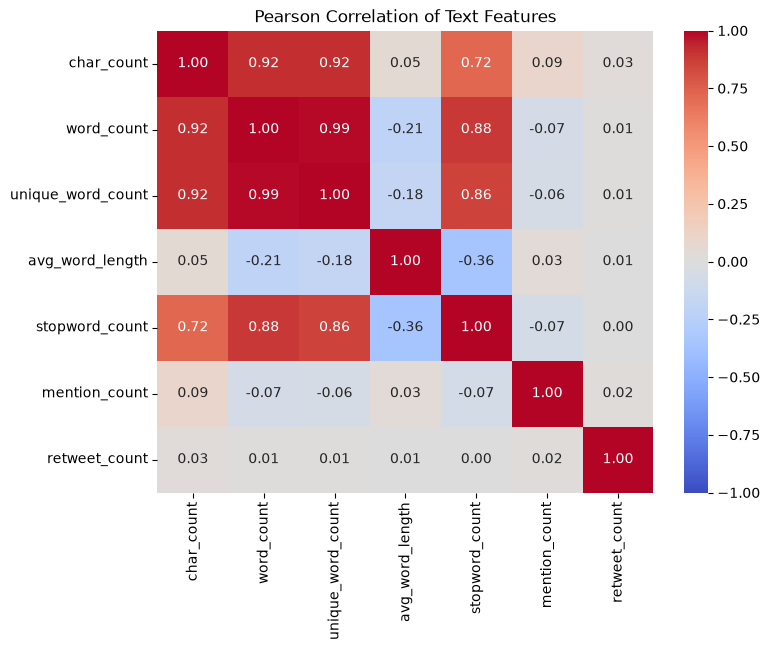

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson Correlation of Text Features")
plt.savefig("../output/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# list each pair once sorted by |r|
rows = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        rows.append((num_cols[i], num_cols[j], corr.iloc[i, j]))

pairs = pd.DataFrame(rows, columns=["feature_1", "feature_2", "r"])
pairs["abs_r"] = pairs["r"].abs()


def strength(a):
    if pd.isna(a):
        return "undefined"
    if a >= 0.7:
        return "strong"
    if a >= 0.4:
        return "moderate"
    return "weak"


pairs["strength"] = pairs["abs_r"].apply(strength)
pairs = pairs.sort_values("abs_r", ascending=False).reset_index(drop=True)
pairs[["feature_1", "feature_2", "r", "strength"]].round(3)

,feature_1,feature_2,r,strength
0,word_count,unique_word_count,0.985,strong
1,char_count,unique_word_count,0.917,strong
2,char_count,word_count,0.916,strong
3,word_count,stopword_count,0.885,strong
4,unique_word_count,stopword_count,0.856,strong
5,char_count,stopword_count,0.723,strong
6,avg_word_length,stopword_count,-0.358,weak
7,word_count,avg_word_length,-0.206,weak
8,unique_word_count,avg_word_length,-0.177,weak
9,char_count,mention_count,0.094,weak


Interpretation of the Correlation Results
Strong relationships (|r| ≥ 0.7)
- word_count and unique_word_count have a very strong correlation (r = 0.99). This means that tweets usually contain many words that appear only once.
- char_count is strongly related to both word_count and unique_word_count (r = 0.92). Tweets with more words usually contain more characters.
- stopword_count is also related to word_count (r = 0.88) and char_count (r = 0.72). Longer tweets usually contain more common words, such as to, the, and my.
These results show that several features measure almost the same thing: tweet length.

Weak relationships (|r| < 0.4)
- avg_word_length and stopword_count have a weak negative correlation (r = −0.36). This may be because stop words are usually short.
- avg_word_length and char_count have almost no correlation (r = 0.05). Longer tweets contain more characters mainly because they have more words, not necessarily longer words.
- retweet_count and mention_count have almost no correlation with the other features. Most tweets have zero retweets (94.7%), while 89.2% have only one mention.
Implication for modelling

char_count, word_count, and unique_word_count provide very similar information. Therefore, using just one of them may be enough, instead of adding all three to the model.

### Correlation does not imply causation

A high correlation only says two variables move together; it does not say one causes the other. Examples from this data:

- `word_count` and `unique_word_count` rise together because both are driven by a third factor, the tweet length. Their link is mostly mechanical: a tweet with more words simply has more chances to contain different words.
- If longer tweets turn out to be more negative, this does not mean that writing a longer tweet makes a customer angry. People with a bad experience (a delay, lost luggage) may write more to explain it. So the direction could be the other way round, and hidden confounders such as the type of problem or the airline can drive both length and sentiment.

## 3.4 Tokenization



In [18]:
tokens = tdf["cleaned_text"].str.split()

all_tokens = [w for t in tokens for w in t]          # one flat list of all words
total_tokens = len(all_tokens)
vocab_size = len(set(all_tokens))
n_records = len(tdf)
n_nonempty = (tokens.str.len() > 0).sum()

print("Total tokens:                     ", total_tokens)
print("Unique words (vocabulary size):   ", vocab_size)
print("Average words per record:         ", round(total_tokens / n_records, 2))
print("Average words per non-empty record:", round(total_tokens / n_nonempty, 2))

Total tokens:                      232252
Unique words (vocabulary size):    11346
Average words per record:          16.03
Average words per non-empty record: 16.03


## 3.5 Top 20 words

We count word frequencies before and after removing stop words (very common words such as "the" or "to"). Single-character tokens are also dropped after stop-word removal.

In [19]:
# sklearn stop words + a tiny set of tweet noise words
STOP_WORDS = set(ENGLISH_STOP_WORDS) | {"rt", "amp"}


def remove_stop(word_list):
    # drop stop words and single-character tokens
    return [w for w in word_list if w not in STOP_WORDS and len(w) > 1]


# before stop-word removal
freq_before = pd.DataFrame(Counter(all_tokens).most_common(20), columns=["word", "count"])

# after stop-word removal
tokens_clean = remove_stop(all_tokens)
freq_after = pd.DataFrame(Counter(tokens_clean).most_common(20), columns=["word", "count"])

print("Top 20 BEFORE stop-word removal")
print(freq_before)
print("\nTop 20 AFTER stop-word removal")
print(freq_after)

share = freq_before["word"].isin(STOP_WORDS).mean()
print("\nShare of the before-top-20 that are stop words:", f"{share:.0%}")

Top 20 BEFORE stop-word removal
      word  count
0       to   8557
1      the   5992
2        i   5356
3        a   4557
4      you   4091
5      for   3954
6   flight   3898
7       on   3770
8      and   3697
9       my   3235
10      is   2805
11      in   2569
12      of   2095
13      me   1906
14      it   1876
15    your   1732
16    have   1636
17     was   1583
18     not   1567
19    with   1507

Top 20 AFTER stop-word removal
         word  count
0      flight   3898
1      thanks   1063
2   cancelled   1043
3        just    965
4     service    959
5        help    864
6        time    786
7    customer    747
8         i'm    704
9       hours    676
10    flights    644
11       hold    638
12      plane    630
13      thank    601
14       need    552
15      can't    537
16    delayed    537
17       gate    512
18       it's    499
19  flightled    498

Share of the before-top-20 that are stop words: 95%


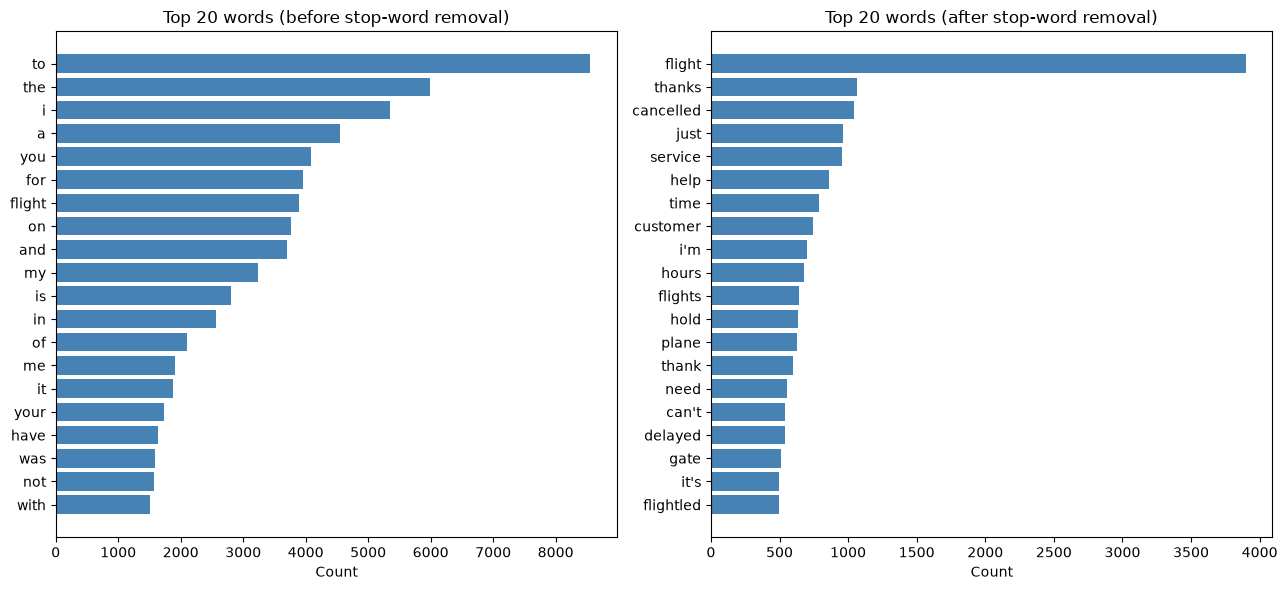

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, data, title in [(axes[0], freq_before, "Top 20 words (before stop-word removal)"),
                        (axes[1], freq_after, "Top 20 words (after stop-word removal)")]:
    ax.barh(data["word"], data["count"], color="steelblue")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Count")

plt.tight_layout()
plt.savefig("../output/figures/word_frequency_top20.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.6 Group comparison: negative vs positive tweets

We compare negative and positive tweets because they give the clearest contrast in wording. Neutral tweets are left out of the comparison (they are printed once for reference only).

In [21]:
group_stats = tdf.groupby("airline_sentiment").agg(
    num_tweets=("tweet_id", "count"),
    avg_char_count=("char_count", "mean"),
    avg_word_count=("word_count", "mean"),
    avg_unique_word_count=("unique_word_count", "mean"),
).round(2)

print("Negative vs positive")
print(group_stats.loc[["negative", "positive"]])
print("\nNeutral (reference only)")
print(group_stats.loc[["neutral"]])

Negative vs positive
                   num_tweets  avg_char_count  avg_word_count  \
airline_sentiment                                               
negative                 9082          113.94           18.04   
positive                 2334           86.29           12.52   

                   avg_unique_word_count  
airline_sentiment                         
negative                           16.86  
positive                           11.90  

Neutral (reference only)
                   num_tweets  avg_char_count  avg_word_count  \
airline_sentiment                                               
neutral                  3069           87.29           12.78   

                   avg_unique_word_count  
airline_sentiment                         
neutral                            12.02  


In [22]:
def top_words(sentiment, n=10):
    group_tokens = [w for t in tokens[tdf["airline_sentiment"] == sentiment] for w in t]
    return Counter(remove_stop(group_tokens)).most_common(n)


neg_top = top_words("negative")
pos_top = top_words("positive")

top_table = pd.DataFrame({
    "negative_word": [w for w, c in neg_top],
    "negative_count": [c for w, c in neg_top],
    "positive_word": [w for w, c in pos_top],
    "positive_count": [c for w, c in pos_top],
}, index=range(1, 11))
top_table

,negative_word,negative_count,positive_word,positive_count
1,flight,2912,thanks,599
2,cancelled,907,thank,451
3,service,744,flight,380
4,hours,651,great,234
5,just,618,just,176
6,help,612,service,160
7,hold,608,love,134
8,customer,604,customer,113
9,time,594,guys,108
10,plane,525,good,107


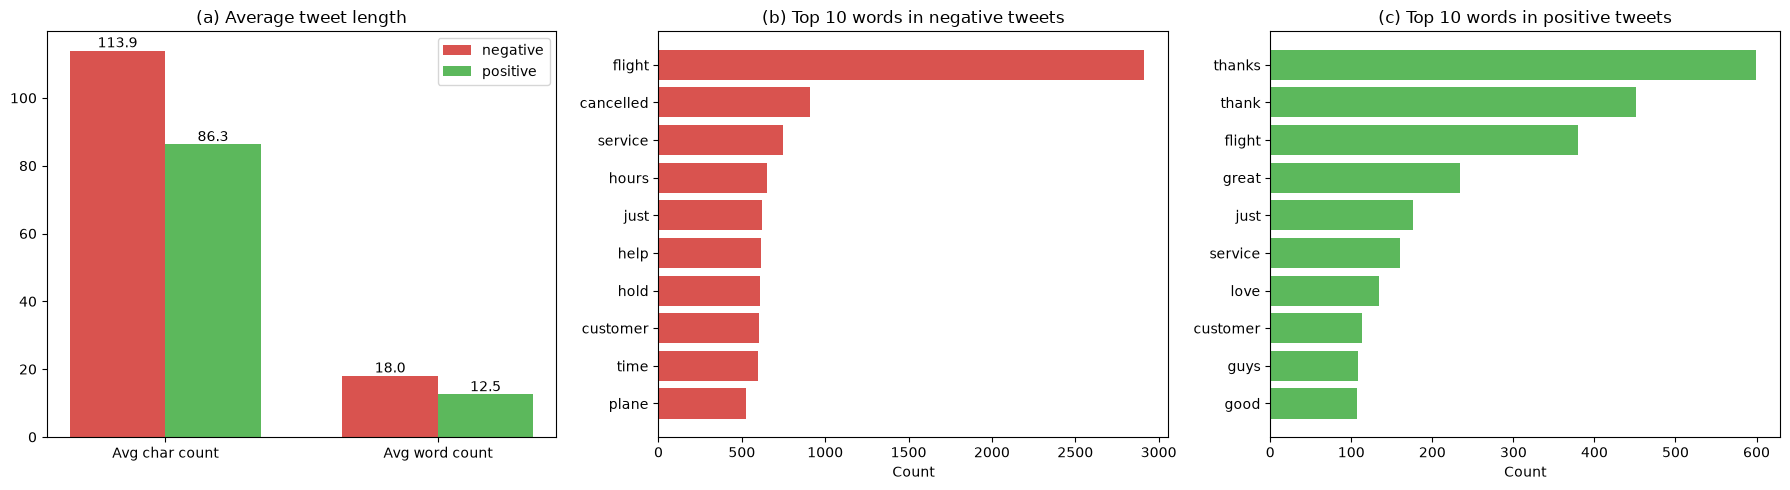

In [23]:
neg_color, pos_color = "#d9534f", "#5cb85c"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) average length per group
metrics = ["avg_char_count", "avg_word_count"]
x = np.arange(len(metrics))
w = 0.35
b1 = axes[0].bar(x - w / 2, group_stats.loc["negative", metrics], w, color=neg_color, label="negative")
b2 = axes[0].bar(x + w / 2, group_stats.loc["positive", metrics], w, color=pos_color, label="positive")
axes[0].bar_label(b1, fmt="%.1f")
axes[0].bar_label(b2, fmt="%.1f")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Avg char count", "Avg word count"])
axes[0].set_title("(a) Average tweet length")
axes[0].legend()

# (b) top 10 negative words
axes[1].barh([w for w, c in neg_top], [c for w, c in neg_top], color=neg_color)
axes[1].invert_yaxis()
axes[1].set_title("(b) Top 10 words in negative tweets")
axes[1].set_xlabel("Count")

# (c) top 10 positive words
axes[2].barh([w for w, c in pos_top], [c for w, c in pos_top], color=pos_color)
axes[2].invert_yaxis()
axes[2].set_title("(c) Top 10 words in positive tweets")
axes[2].set_xlabel("Count")

plt.tight_layout()
plt.savefig("../output/figures/group_comparison_neg_vs_pos.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
neg_share = pd.crosstab(tdf["airline"], tdf["airline_sentiment"], normalize="index")["negative"]
print("Share of negative tweets per airline:")
print(neg_share.sort_values(ascending=False).round(3))

print("\nTop negative reasons:")
print(tdf["negativereason"].value_counts().head(10))

Share of negative tweets per airline:
airline
US Airways        0.777
American          0.716
United            0.689
Southwest         0.490
Delta             0.430
Virgin America    0.359
Name: negative, dtype: float64

Top negative reasons:
negativereason
Customer Service Issue         2885
Late Flight                    1650
Can't Tell                     1176
Cancelled Flight                829
Lost Luggage                    719
Bad Flight                      575
Flight Booking Problems         523
Flight Attendant Complaints     475
longlines                       177
Damaged Luggage                  73
Name: count, dtype: int64


## 3.7 Insights

Insight 1: Negative tweets are longer than positive tweets
- Observation: Negative tweets are usually longer than positive tweets.
- Evidence: Negative tweets have an average of 113.9 characters and 18 words. Positive tweets have 86.3 characters and 12.5 words, while neutral tweets have 87.3 characters and 12.8 words.
- Interpretation: Customers who have problems with their flights often explain what happened, while happy customers may simply say "thanks". This makes tweet length a useful feature for sentiment analysis, but it does not mean that longer tweets are always negative.
Insight 2: Stop words appear most often in the raw text
- Observation: Most of the top 20 frequent words are stop words.
- Evidence: 19 out of the top 20 words are common words such as to, the, and i. The only meaningful word in the list is flight.
- Interpretation: Common words do not tell us much about what customers are saying. Removing stop words or using TF-IDF can help us focus on more useful words.
Insight 3: Negative and positive tweets use different words
- Observation: Negative and positive tweets often contain different types of words.
- Evidence: Negative tweets frequently contain words such as cancelled, hours, help, and hold. Positive tweets often contain thanks, thank, great, and love.
- Interpretation: Customers mainly complain about flight cancellations, long waiting times, and customer service. Positive tweets are more likely to contain words showing appreciation. Some words, such as flight and service, appear in both groups, so they do not always tell us the sentiment.
Insight 4: Most tweets are negative, but the results differ by airline
- Observation: Negative tweets make up the largest group, but some airlines receive more negative tweets than others.
- Evidence: After removing duplicates, there are 9,082 negative tweets (62.7%), 3,069 neutral tweets, and 2,334 positive tweets. US Airways has the highest negative share at 77.7%, followed by American Airlines at 71.6% and United at 68.9%. Virgin America has 35.9%, while Delta has 43.0%.
- Interpretation: Since most tweets are negative, a model could get around 63% accuracy simply by predicting the negative class every time. Therefore, we should use a stratified train-test split and check F1-score for each class, not just accuracy. Also, people may be more likely to tweet when they have a problem, so these results do not represent all customers' opinions.
Insight 5: Some text features provide almost the same information
- Observation: Several features related to tweet length are strongly connected.
- Evidence: Word count and unique word count have a correlation of 0.99, while character count and word count have a correlation of 0.92. Word count and stop-word count have a correlation of 0.88. Retweet count has almost no correlation with the other features.
- Interpretation: Using all the length features may not improve the model much because they provide similar information. One length feature combined with TF-IDF features may be enough. Also, 94.7% of tweets have zero retweets, so retweet count is unlikely to be very useful.
Insight 6: The original dataset contains some text errors
- Observation: Some tweets contain unusual words such as flightled and flightr.
- Evidence: We found 491 raw tweets containing "Flightled" and 161 containing "Late Flightr". These errors appear to be related to automatic text replacement in the original dataset.
- Interpretation: These words are probably data-cleaning errors rather than words customers actually used. We kept the original text unchanged during this analysis, but this issue should be mentioned as a limitation. In future work, we could correct these words to improve the text quality.

## 3.8 Saved files check

In [25]:
print("Figures in ../output/figures/:")
for f in sorted(os.listdir("../output/figures")):
    print(" -", f)

print("\ncleaned_text.csv exists:", os.path.exists("../output/cleaned_text.csv"))

Figures in ../output/figures/:
 - confusion_matrix.png
 - correlation_heatmap.png
 - group_comparison_neg_vs_pos.png
 - model_comparison.png
 - sampling_comparison.png
 - word_frequency_top20.png

cleaned_text.csv exists: True


# Member 4: Machine Learning (Supervised Text Classification + K-Means)

**Input:** `../output/cleaned_text.csv` (created by Member 3's section: it holds the original `text`, the `cleaned_text` column and the label `airline_sentiment`).

**Goal:** (1) predict the tweet sentiment (negative / neutral / positive) from the text with TF-IDF + a classifier, and (2) group the tweets with K-Means without using the labels, then compare the clusters with the real labels.

## 4.0 Setup and data

In [26]:
RANDOM_STATE = 42
os.makedirs("../output/figures", exist_ok=True)
ml = pd.read_csv("../output/cleaned_text.csv")
ml["cleaned_text"] = ml["cleaned_text"].fillna("")

# a tweet that is empty after cleaning (e.g. only a mention + a link) has no words to learn from
n_empty = (ml["cleaned_text"].str.strip() == "").sum()
ml = ml[ml["cleaned_text"].str.strip() != ""].reset_index(drop=True)
print("Empty cleaned tweets removed:", n_empty)
print("Records used for ML:", ml.shape[0])
print(ml["airline_sentiment"].value_counts())
print((ml["airline_sentiment"].value_counts(normalize=True) * 100).round(1))

Empty cleaned tweets removed: 0
Records used for ML: 14485
airline_sentiment
negative    9082
neutral     3069
positive    2334
Name: count, dtype: int64
airline_sentiment
negative    62.7
neutral     21.2
positive    16.1
Name: proportion, dtype: float64


## 4.1 Supervised text classification

**Target:** `airline_sentiment`. The classes are imbalanced (about 63% negative), so a model that always says "negative" already gets about 63% accuracy. For this reason we look at **macro** precision / recall / F1 (every class counts equally) and not only at accuracy.

### 4.1.1 Train / test split
80% train, 20% test, **stratified** so each split keeps the same class proportions.

In [27]:
X = ml["cleaned_text"]
y = ml["airline_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
print("\nTrain distribution (%):\n", (y_train.value_counts(normalize=True) * 100).round(1))
print("\nTest distribution (%):\n", (y_test.value_counts(normalize=True) * 100).round(1))

majority_acc = (y_test == y_train.mode()[0]).mean()
print(f"\nMajority-class baseline accuracy: {majority_acc:.4f}")

Train: 11588 | Test: 2897

Train distribution (%):
 airline_sentiment
negative    62.7
neutral     21.2
positive    16.1
Name: proportion, dtype: float64

Test distribution (%):
 airline_sentiment
negative    62.7
neutral     21.2
positive    16.1
Name: proportion, dtype: float64

Majority-class baseline accuracy: 0.6269


### 4.1.2 TF-IDF features and two classifiers
TF-IDF turns every tweet into a vector: a word gets a high weight if it is frequent in the tweet but rare in the other tweets. **The vectorizer is fitted on the training set only**, so no information from the test set leaks into the model.

We train two suitable classifiers on the same features: **Multinomial Naive Bayes** and **Logistic Regression**.

In [28]:
def evaluate(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f}

tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=2, sublinear_tf=True)
Xtr_uni = tfidf_uni.fit_transform(X_train)
Xte_uni = tfidf_uni.transform(X_test)
print("TF-IDF matrix (train):", Xtr_uni.shape)

nb = MultinomialNB().fit(Xtr_uni, y_train)
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xtr_uni, y_train)

preds = {"Multinomial NB (unigrams)": nb.predict(Xte_uni),
         "Logistic Regression (unigrams)": lr.predict(Xte_uni)}
results = [evaluate(name, y_test, p) for name, p in preds.items()]
pd.DataFrame(results).round(4)

TF-IDF matrix (train): (11588, 4959)


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Multinomial NB (unigrams),0.7218,0.7931,0.5147,0.5516
1,Logistic Regression (unigrams),0.7963,0.7722,0.6871,0.7193


### 4.1.3 Bonus: model improvement (n-grams + hyperparameter tuning)
We improve Logistic Regression by tuning, with 5-fold stratified cross-validation **on the training set only** (the test set stays untouched until the final evaluation):
- `ngram_range`: unigrams vs. unigrams + bigrams (bigrams capture phrases such as "customer service" or "not good"),
- `C`: inverse regularization strength,
- `class_weight`: `None` vs. `balanced` (gives more weight to the smaller neutral/positive classes).

The score used to choose the best setting is **macro-F1**, because of the class imbalance.

In [29]:
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.5, 1, 2, 5, 10],
    "clf__class_weight": [None, "balanced"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipe, param_grid, scoring="f1_macro", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV macro-F1 (train only): {grid.best_score_:.4f}")

best_model = grid.best_estimator_
preds["Logistic Regression (tuned, n-grams)"] = best_model.predict(X_test)
results.append(evaluate("Logistic Regression (tuned, n-grams)", y_test, preds["Logistic Regression (tuned, n-grams)"]))
comparison = pd.DataFrame(results).round(4)
comparison

Best parameters: {'clf__C': 2, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
Best CV macro-F1 (train only): 0.7425


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Multinomial NB (unigrams),0.7218,0.7931,0.5147,0.5516
1,Logistic Regression (unigrams),0.7963,0.7722,0.6871,0.7193
2,"Logistic Regression (tuned, n-grams)",0.7922,0.7398,0.7400,0.7391


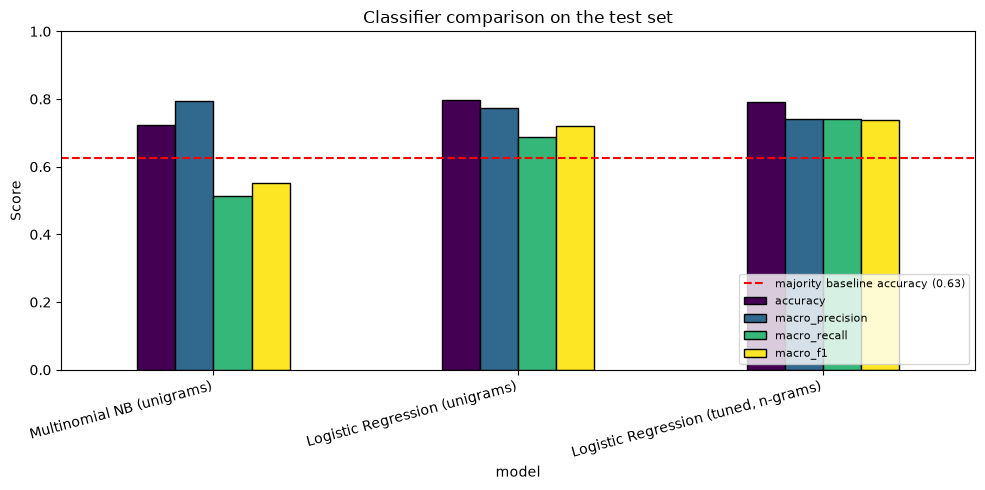

In [30]:
# figure: model comparison
plot_df = comparison.set_index("model")[["accuracy", "macro_precision", "macro_recall", "macro_f1"]]
ax = plot_df.plot(kind="bar", figsize=(10, 5), colormap="viridis", edgecolor="black")
ax.axhline(majority_acc, color="red", linestyle="--", label=f"majority baseline accuracy ({majority_acc:.2f})")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Classifier comparison on the test set")
ax.set_xticklabels(plot_df.index, rotation=15, ha="right")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("../output/figures/model_comparison.png", dpi=150)
plt.show()

### 4.1.4 Final model: metrics and confusion matrix
The final model is the one with the best macro-F1 in the table above.

In [31]:
final_name = comparison.sort_values("macro_f1", ascending=False).iloc[0]["model"]
print("Final model:", final_name)

y_pred = preds[final_name]
labels = ["negative", "neutral", "positive"]

final_metrics = evaluate(final_name, y_test, y_pred)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)
report_text = classification_report(y_test, y_pred, labels=labels, digits=3)
print(f"Accuracy: {final_metrics['accuracy']:.4f}")
print(f"Macro    precision/recall/F1: {final_metrics['macro_precision']:.3f} / {final_metrics['macro_recall']:.3f} / {final_metrics['macro_f1']:.3f}")
print(f"Weighted precision/recall/F1: {p_w:.3f} / {r_w:.3f} / {f_w:.3f}\n")
print(report_text)

Final model: Logistic Regression (tuned, n-grams)
Accuracy: 0.7922
Macro    precision/recall/F1: 0.740 / 0.740 / 0.739
Weighted precision/recall/F1: 0.797 / 0.792 / 0.794

              precision    recall  f1-score   support

    negative      0.879     0.861     0.870      1816
     neutral      0.595     0.656     0.624       614
    positive      0.745     0.702     0.723       467

    accuracy                          0.792      2897
   macro avg      0.740     0.740     0.739      2897
weighted avg      0.797     0.792     0.794      2897



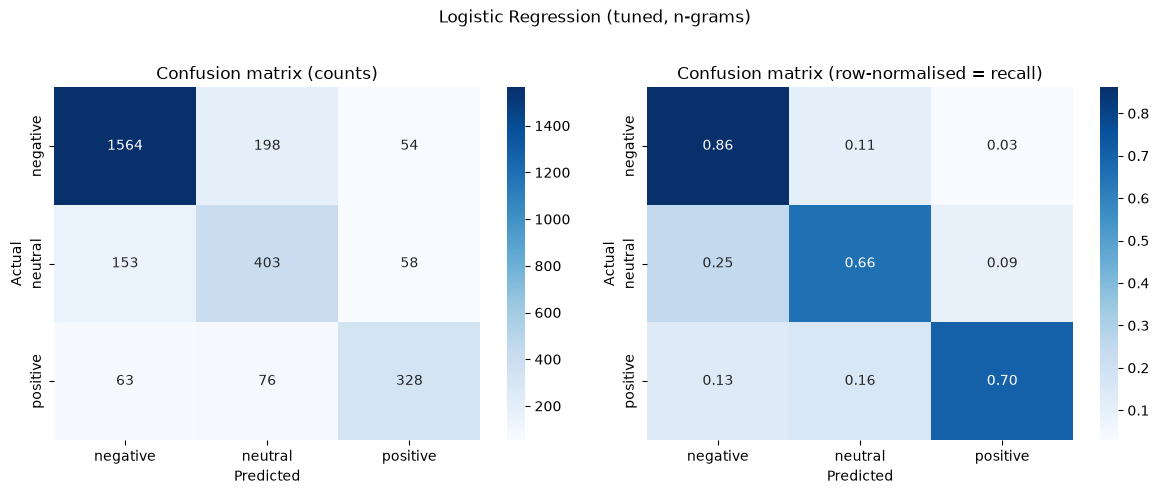

In [32]:
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalised = recall)")
for a in axes:
    a.set_xlabel("Predicted")
    a.set_ylabel("Actual")
plt.suptitle(f"{final_name}", y=1.02)
plt.tight_layout()
plt.savefig("../output/figures/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.1.5 What did the model learn?
The largest Logistic Regression coefficients show which words push a tweet towards each class.

In [33]:
# (the tuned pipeline is the final model; for a different winner, replace best_model accordingly)
assert final_name.startswith("Logistic Regression (tuned"), "final model changed: update this cell"
vec = best_model.named_steps["tfidf"]
clf = best_model.named_steps["clf"]
feat = np.array(vec.get_feature_names_out())
top_words = {}
for i, cls in enumerate(clf.classes_):
    idx = np.argsort(clf.coef_[i])[::-1][:10]
    top_words[cls] = list(feat[idx])
pd.DataFrame(top_words)

,negative,neutral,positive
0,not,is there,great
1,no,hi,thanks
2,delayed,can you,awesome
3,hours,do you,love
4,worst,is your,amazing
5,why,can,thank
6,your,dm,appreciate
7,nothing,any,best
8,cancelled,do,thx
9,hour,destinationdragons,the best


In [34]:
# error analysis: a few misclassified tweets (original text is kept untouched in `ml`)
err = ml.loc[X_test.index].assign(predicted=y_pred)
err = err[err["airline_sentiment"] != err["predicted"]]
print("Misclassified:", len(err), "of", len(X_test))
pd.set_option("display.max_colwidth", 110)
err[["text", "airline_sentiment", "predicted"]].head(8)

Misclassified: 602 of 2897


,text,airline_sentiment,predicted
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",neutral,negative
9042,.@USAirways I did but the more eyes I have looking for Pandu the better chance I have of bringing him home.,negative,positive
7065,"@JetBlue wow, keeping up with the times...",positive,negative
11223,"@USAirways Flight US 723 from @DublinAirport to @PHLAirport passing over @LoveLoughNeagh at 20,000 ft this...",neutral,negative
9350,@USAirways power trip. I felt completely threatened and unsafe and I am so angry. Derrick Bussey. DCA. Wo...,negative,positive
1550,@united JP - DM message who? Can't get a DM through to @united,negative,neutral
7976,"@JetBlue looks like their inflatable car seats got left on the plane, so I guess they'll be back sometime!...",negative,neutral
11778,"@USAirways me too. In the future, have a better harsh weather preparedness plan. So much of your staff cal...",negative,positive


### 4.1.6 Interpretation and limitations

- **Better than the baseline.** The final model reaches about 79% accuracy against 62.7% for always predicting "negative", and a macro-F1 of about 0.74. It learned something real from the text.
- **Why macro-F1 chose the final model.** Plain Logistic Regression has a slightly higher accuracy, but the tuned model (bigrams, `class_weight="balanced"`, C=2) has better macro recall and macro-F1 because it stops favouring the majority class. Naive Bayes has high precision but very low recall on neutral/positive tweets (macro recall about 0.51): it predicts "negative" too often.
- **Negative is easiest, neutral is hardest.** Negative tweets get F1 about 0.87. Neutral tweets get F1 about 0.62 and are mostly confused with negative ones (see the confusion matrix): neutral tweets are often questions or short statements that contain no strong sentiment words ("is there", "can you", "dm").
- **What the model learned.** Negative: "not", "delayed", "hours", "worst", "cancelled". Positive: "thanks", "great", "awesome", "love". These are sensible, which is a good sign.

**Limitations**
1. TF-IDF is a bag of words: it ignores word order, context and sarcasm ("thanks for losing my bag" looks positive).
2. The labels were produced by crowd workers and are noisy, especially for the neutral class, so there is a ceiling on the achievable score.
3. Some top words are dataset artefacts and not real sentiment (for example the promotional hashtag `destinationdragons` for neutral), so the model can partly learn about the dataset and not about sentiment.
4. One train/test split on tweets from a single week (February 2015): results may not generalise to other periods or airlines.

### 4.1.7 Save the supervised results

In [35]:
INTERPRETATION = f"""\
1. The final model ({final_name}) reaches accuracy {final_metrics['accuracy']:.3f} vs a majority-class baseline of {majority_acc:.3f}; macro-F1 is {final_metrics['macro_f1']:.3f}.
2. Macro-F1 (not accuracy) was used to pick the model because the classes are imbalanced. Tuning (bigrams, class_weight=balanced, C=2) raised macro-F1 and recall for the minority classes, at a very small cost in accuracy. Naive Bayes had high precision but low recall on neutral/positive tweets.
3. Negative tweets are classified best (F1 0.87); neutral is the hardest class (F1 0.62) and is mostly confused with negative, because neutral tweets are often questions or short statements without sentiment words.
4. The strongest words per class are sensible (negative: not, delayed, hours, worst, cancelled; positive: thanks, great, awesome, love).

LIMITATIONS
- TF-IDF ignores word order, context and sarcasm.
- Crowd-sourced labels are noisy, particularly for the neutral class.
- Some top words are dataset artefacts (e.g. the promo hashtag 'destinationdragons').
- A single train/test split on one week of tweets (Feb 2015): limited generalisation.
"""

In [36]:
with open("../output/model_metrics.txt", "w", encoding="utf-8") as f:
    f.write("SUPERVISED TEXT CLASSIFICATION - Twitter US Airline Sentiment\n")
    f.write("=" * 62 + "\n\n")
    f.write(f"Records used: {len(ml)} (empty cleaned tweets removed: {n_empty})\n")
    f.write(f"Split: 80% train ({len(X_train)}) / 20% test ({len(X_test)}), stratified, random_state={RANDOM_STATE}\n")
    f.write("Features: TF-IDF (fitted on the training set only, min_df=2, sublinear_tf=True)\n")
    f.write("Target: airline_sentiment (negative / neutral / positive)\n")
    f.write(f"Majority-class baseline accuracy: {majority_acc:.4f}\n\n")
    f.write("MODEL COMPARISON (test set)\n")
    f.write(comparison.to_string(index=False) + "\n\n")
    f.write(f"Tuning (GridSearchCV, 5-fold, scoring=macro-F1, train only)\n")
    f.write(f"  best params: {grid.best_params_}\n")
    f.write(f"  best CV macro-F1: {grid.best_score_:.4f}\n\n")
    f.write(f"FINAL MODEL: {final_name}\n")
    f.write(f"  Accuracy:           {final_metrics['accuracy']:.4f}\n")
    f.write(f"  Macro precision:    {final_metrics['macro_precision']:.4f}\n")
    f.write(f"  Macro recall:       {final_metrics['macro_recall']:.4f}\n")
    f.write(f"  Macro F1:           {final_metrics['macro_f1']:.4f}\n")
    f.write(f"  Weighted precision: {p_w:.4f}\n  Weighted recall:    {r_w:.4f}\n  Weighted F1:        {f_w:.4f}\n\n")
    f.write("Per-class report:\n" + report_text + "\n")
    f.write("Confusion matrix (rows = actual, columns = predicted; order: negative, neutral, positive):\n")
    f.write(pd.DataFrame(cm, index=labels, columns=labels).to_string() + "\n\n")
    f.write("Top words per class (largest coefficients):\n")
    for cls, words in top_words.items():
        f.write(f"  {cls}: {', '.join(words)}\n")
    f.write("\nINTERPRETATION\n")
    f.write(INTERPRETATION)
print(open("../output/model_metrics.txt", encoding="utf-8").read())

SUPERVISED TEXT CLASSIFICATION - Twitter US Airline Sentiment

Records used: 14485 (empty cleaned tweets removed: 0)
Split: 80% train (11588) / 20% test (2897), stratified, random_state=42
Features: TF-IDF (fitted on the training set only, min_df=2, sublinear_tf=True)
Target: airline_sentiment (negative / neutral / positive)
Majority-class baseline accuracy: 0.6269

MODEL COMPARISON (test set)
                               model  accuracy  macro_precision  macro_recall  macro_f1
           Multinomial NB (unigrams)    0.7218           0.7931        0.5147    0.5516
      Logistic Regression (unigrams)    0.7963           0.7722        0.6871    0.7193
Logistic Regression (tuned, n-grams)    0.7922           0.7398        0.7400    0.7391

Tuning (GridSearchCV, 5-fold, scoring=macro-F1, train only)
  best params: {'clf__C': 2, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
  best CV macro-F1: 0.7425

FINAL MODEL: Logistic Regression (tuned, n-grams)
  Accuracy:         

## 4.2 K-Means clustering (unsupervised)

K-Means never sees the labels: it only groups tweets whose vectors are close to each other. We use the labels **afterwards**, just to check what the clusters mean.

### 4.2.1 Numerical representation: TF-IDF + TruncatedSVD
- Here stop words are **removed** (and very common words dropped with `max_df=0.5`), otherwise words like "the" or "to" would dominate the distances and the clusters would be meaningless.
- TF-IDF is a large sparse matrix and K-Means works poorly in thousands of sparse dimensions, so we reduce it with **TruncatedSVD** and then L2-normalise the rows (so Euclidean K-Means behaves like cosine similarity).

The number of SVD components is chosen by a small experiment. Very few components give a high but misleading silhouette (almost all the information is thrown away), so we want a compromise.

In [37]:
tfidf_km = TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english", sublinear_tf=True)
T = tfidf_km.fit_transform(ml["cleaned_text"])
terms = np.array(tfidf_km.get_feature_names_out())
print("TF-IDF matrix for clustering:", T.shape)

rows = []
for n_comp in [10, 30, 50, 100]:
    svd_try = TruncatedSVD(n_components=n_comp, random_state=RANDOM_STATE)
    Z_try = Normalizer().fit_transform(svd_try.fit_transform(T))
    km_try = KMeans(n_clusters=8, n_init=10, random_state=RANDOM_STATE).fit(Z_try)
    rows.append({"svd_components": n_comp,
                 "variance_explained": round(svd_try.explained_variance_ratio_.sum(), 3),
                 "silhouette_k8": round(silhouette_score(Z_try, km_try.labels_), 3)})
pd.DataFrame(rows)

TF-IDF matrix for clustering: (14485, 3890)


,svd_components,variance_explained,silhouette_k8
0,10,0.065,0.389
1,30,0.124,0.114
2,50,0.170,0.090
3,100,0.256,0.055


With 10 components the silhouette is high (about 0.39) but only about 6% of the variance is kept, so it mostly reflects a few very tight groups of near-identical short tweets. We use **50 components** as a compromise between information kept and a compact space.

In [38]:
N_COMPONENTS = 50
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
Z = Normalizer().fit_transform(svd.fit_transform(T))
var_expl = svd.explained_variance_ratio_.sum()
print(f"SVD components: {N_COMPONENTS} | variance explained: {var_expl:.3f}")

SVD components: 50 | variance explained: 0.170


### 4.2.2 Choosing k (experiment)
We run K-Means for k = 2 ... 12 and look at three things: the **inertia** (elbow), the **silhouette score**, and the **size of the smallest cluster**. We do not just use k=3 because the number of sentiment classes is 3: K-Means groups tweets by *vocabulary* (topics), and an airline-tweet corpus has more than three topics.

In [39]:
ks = list(range(2, 13))
inertias, sils, min_sizes = [], [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inertias.append(km_k.inertia_)
    sils.append(silhouette_score(Z, km_k.labels_))
    min_sizes.append(np.bincount(km_k.labels_).min())

k_table = pd.DataFrame({"k": ks, "inertia": np.round(inertias, 1),
                        "silhouette": np.round(sils, 4), "smallest_cluster": min_sizes})
k_table

,k,inertia,silhouette,smallest_cluster
0,2,12600.3,0.0387,3278
1,3,12204.0,0.0531,994
2,4,11847.5,0.0657,956
3,5,11500.8,0.0796,548
4,6,11300.3,0.0768,928
5,7,11037.7,0.0770,860
6,8,10815.7,0.0905,543
7,9,10541.8,0.0952,531
8,10,10388.3,0.0989,518
9,11,10257.0,0.1002,534


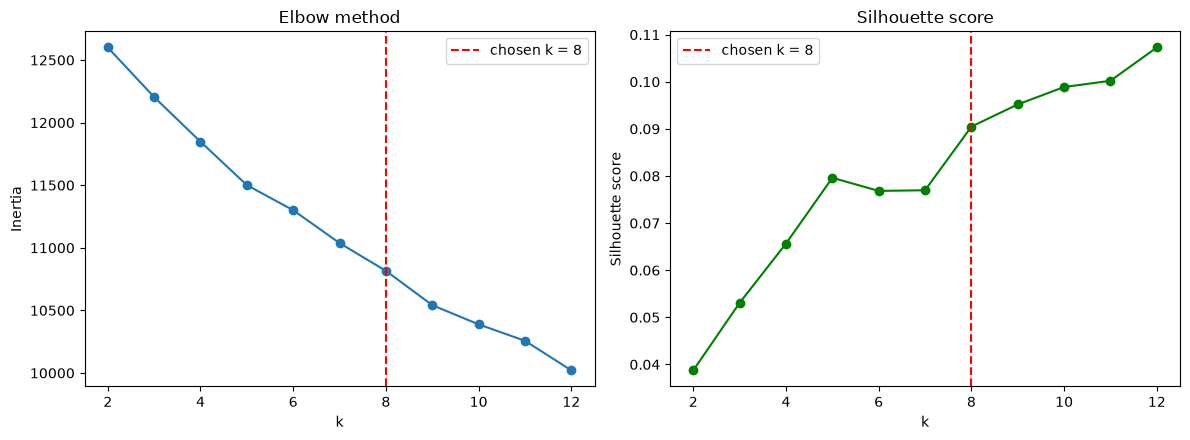

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ks, inertias, marker="o")
axes[0].axvline(8, color="red", linestyle="--", label="chosen k = 8")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow method"); axes[0].legend()
axes[1].plot(ks, sils, marker="o", color="green")
axes[1].axvline(8, color="red", linestyle="--", label="chosen k = 8")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score"); axes[1].set_title("Silhouette score"); axes[1].legend()
plt.tight_layout()
plt.savefig("../output/figures/kmeans_k_selection.png", dpi=150)
plt.show()

**Why k = 8.**
- The inertia curve bends gradually (no sharp elbow, typical for text): the gain per extra cluster becomes small after about k = 6-8.
- The silhouette score is low for every k (below about 0.11) and keeps rising slowly, with no clear peak: short, sparse tweets overlap a lot, so clusters are not well separated. Because it has no peak, we do not pick the maximum blindly.
- We inspected k = 6, 8 and 10 (top terms of each cluster). At **k = 8** every cluster has more than 500 tweets and a clearly different theme. With k = 6 distinct themes (waiting at the gate, delays) are merged, and with k = 10 the positive tweets are split into near-duplicate "thank"/"thanks" clusters and an extra cluster of noisy tokens appears.

### 4.2.3 Final K-Means model (k = 8)

In [41]:
K = 8
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
ml["cluster"] = kmeans.labels_

sizes = ml["cluster"].value_counts().sort_index()
sil = silhouette_score(Z, kmeans.labels_)
print(f"Silhouette score (k={K}): {sil:.4f}\n")
print("Records per cluster:")
print(sizes.to_string())

Silhouette score (k=8): 0.0905

Records per cluster:
cluster
0    2450
1    2448
2     905
3    5413
4     543
5     705
6     883
7    1138


### 4.2.4 Top terms per cluster
The centroids live in the SVD space, so we map them back to the word space (`inverse_transform`) and take the terms with the largest weights.

In [42]:
centroids_words = svd.inverse_transform(kmeans.cluster_centers_)
top_terms = {c: list(terms[np.argsort(centroids_words[c])[::-1][:10]]) for c in range(K)}

# label mix per cluster
ct = pd.crosstab(ml["cluster"], ml["airline_sentiment"])[["negative", "neutral", "positive"]]
ct_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

summary_df = pd.DataFrame({"size": sizes,
                           "top_terms": [", ".join(top_terms[c][:8]) for c in range(K)],
                           "%negative": ct_pct["negative"], "%neutral": ct_pct["neutral"], "%positive": ct_pct["positive"]})
pd.set_option("display.max_colwidth", 90)
summary_df

,size,top_terms,%negative,%neutral,%positive
cluster,,,,,
0,2450,"flight, cancelled, flightled, late, delayed, tomorrow, help, just",75.1,18.1,6.7
1,2448,"way, make, ll, ticket, airport, check, trying, best",58.9,31.0,10.1
2,905,"service, customer, worst, terrible, flight, poor, line, phone",79.4,7.0,13.6
3,5413,"just, flights, help, bag, don, like, need, phone",62.3,24.9,12.8
4,543,"thank, great, flight, just, response, help, ok, ll",13.3,12.2,74.6
5,705,"time, flight, wait, flying, departure, check, just, delayed",75.0,13.8,11.2
6,883,"thanks, flight, just, great, got, help, guys, response",25.7,15.7,58.6
7,1138,"plane, gate, sitting, flight, agent, ua, crew, waiting",77.2,13.5,9.2


### 4.2.5 What does each cluster represent?
(Interpretation based on the top terms above and a few tweets read from each cluster.)

In [43]:
# guard: each description is tied to a keyword that must appear in the cluster's top terms,
# so the text can never silently describe the wrong cluster if the data or seed changes
cluster_meaning = {
    0: ("cancelled", "Cancellations and delays (cancelled, flightled, late, delayed, tomorrow): mostly negative."),
    1: ("ticket", "Ticket, check-in and change requests (ticket, airport, check, change, trying): mixed, with the most neutral tweets of all clusters."),
    2: ("service", "Customer-service complaints (service, customer, worst, terrible, poor): the most negative cluster."),
    3: ("help", "General catch-all cluster (help, flights, bag, phone, need): the largest cluster, with a label mix close to that of the whole dataset."),
    4: ("thank", "Short thank-you / positive replies (thank, great, response): mostly positive."),
    5: ("wait", "Waiting time and departure delays (time, wait, departure, delayed): mostly negative."),
    6: ("thanks", "Thanks and praise for help received (thanks, great, guys, response): mostly positive."),
    7: ("gate", "Stuck at the gate / on the plane (plane, gate, sitting, agent, crew, waiting): mostly negative."),
}
for c, (kw, _) in cluster_meaning.items():
    assert kw in top_terms[c], f"cluster {c}: '{kw}' not in top terms -> update cluster_meaning"

for c in range(K):
    print(f"Cluster {c} (n={sizes[c]}): {cluster_meaning[c][1]}")
    print("   example tweets:")
    for t in ml.loc[ml["cluster"] == c, "text"].sample(2, random_state=1):
        print("    -", t[:110])

Cluster 0 (n=2450): Cancellations and delays (cancelled, flightled, late, delayed, tomorrow): mostly negative.
   example tweets:
    - @AmericanAir please help my flight appears Cancelled Flight 1503 from ft. Lauderdale to Dallas to LAX. Is ther
    - @USAirways rebooked for Tuesday. Arriving too Late Flight for on Tuesday to start the class. Cancelled Flightl
Cluster 1 (n=2448): Ticket, check-in and change requests (ticket, airport, check, change, trying): mixed, with the most neutral tweets of all clusters.
   example tweets:
    - @united I have a voucher that expires next week, can I get an extension on it before it expires?
    - @united yup, it just happens way too often...5 times in the last 12 months
Cluster 2 (n=905): Customer-service complaints (service, customer, worst, terrible, poor): the most negative cluster.
   example tweets:
    - @AmericanAir would you like any additional details of my issue? Airport, flight, agent name? Or are you happy 
    - @united @CheerTymeDad

### 4.2.6 Comparing the clusters with the real labels
Cluster IDs are arbitrary, so we do not expect "cluster 0 = negative". We compare at a high level with a cross-tabulation, the **Adjusted Rand Index** (0 = random agreement, 1 = identical) and **Normalized Mutual Information**.

ARI: 0.025 | NMI: 0.066 | purity: 0.670 | majority-class share: 0.627

Counts (rows = cluster, columns = real label):
airline_sentiment  negative  neutral  positive
cluster                                       
0                      1841      444       165
1                      1441      759       248
2                       719       63       123
3                      3374     1347       692
4                        72       66       405
5                       529       97        79
6                       227      139       517
7                       879      154       105


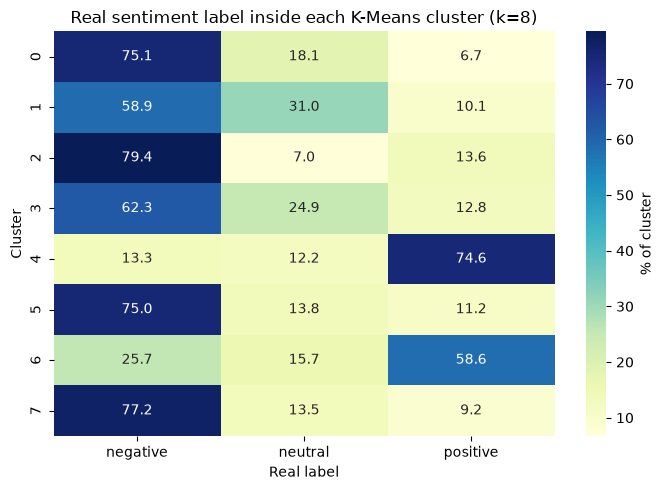

In [44]:
ari = adjusted_rand_score(ml["airline_sentiment"], ml["cluster"])
nmi = normalized_mutual_info_score(ml["airline_sentiment"], ml["cluster"])
purity = ct.max(axis=1).sum() / ct.values.sum()
print(f"ARI: {ari:.3f} | NMI: {nmi:.3f} | purity: {purity:.3f} | majority-class share: {ct.sum().max()/ct.values.sum():.3f}")
print("\nCounts (rows = cluster, columns = real label):")
print(ct)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(ct_pct, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "% of cluster"})
ax.set_title("Real sentiment label inside each K-Means cluster (k=8)")
ax.set_xlabel("Real label"); ax.set_ylabel("Cluster")
plt.tight_layout()
plt.savefig("../output/figures/cluster_vs_labels.png", dpi=150)
plt.show()

**Reading the comparison.** The ARI and NMI are close to 0, so the clusters do **not** reproduce the three sentiment classes, and that is expected: K-Means groups tweets by shared vocabulary (the topic), not by sentiment. Still, some clusters lean clearly towards a label: the two "thanks" clusters are mostly positive, while the customer-service, gate and cancellation clusters are 75-80% negative. The big catch-all cluster has a label mix close to the whole dataset. So the text carries sentiment information, but topic and sentiment are different dimensions, and this is why a supervised model (which uses the labels) is needed for sentiment prediction.

In [45]:
CLUSTER_INTERPRETATION = f"""\
- K-Means is unsupervised: it never used the labels. It grouped tweets by shared vocabulary.
- TF-IDF (stop words removed) + TruncatedSVD({N_COMPONENTS} components, {var_expl*100:.1f}% of the variance) + L2 normalisation.
- k was chosen by experiment (k=2..12, inertia, silhouette, smallest-cluster size, reading top terms), not fixed to 3 (the number of classes): silhouette has no clear peak and is low for every k (short, sparse tweets), the elbow is gradual after k~6-8, and k=8 gives clusters with >500 tweets and distinct themes (k=6 merges themes, k=10 splits the positive tweets into near-duplicate clusters).
- The silhouette is low ({sil:.3f}): clusters overlap and are not well separated, which is normal for short tweets. The clusters are useful for exploring topics but are not sharp.
- Against the real labels: ARI={ari:.3f}, NMI={nmi:.3f} (both near 0). The clusters follow topic, not sentiment, so cluster IDs do not match class IDs. Some clusters still lean to a label: thank-you clusters are mostly positive; customer-service, gate and cancellation clusters are 75-80% negative.
"""

with open("../output/cluster_summary.txt", "w", encoding="utf-8") as f:
    f.write("K-MEANS CLUSTERING - Twitter US Airline Sentiment\n")
    f.write("=" * 52 + "\n\n")
    f.write(f"Records clustered: {len(ml)}\n")
    f.write(f"Representation: TF-IDF (min_df=3, max_df=0.5, English stop words removed) -> TruncatedSVD({N_COMPONENTS}) -> L2 normalisation\n")
    f.write(f"Chosen k: {K}   (random_state={RANDOM_STATE}, n_init=10)\n")
    f.write(f"Silhouette score: {sil:.4f}\n")
    f.write(f"Inertia: {kmeans.inertia_:.1f}\n\n")
    f.write("k selection experiment (SVD space):\n" + k_table.to_string(index=False) + "\n\n")
    f.write("CLUSTER SIZES, TOP TERMS AND MEANING\n")
    for c in range(K):
        f.write(f"\nCluster {c}: {sizes[c]} records ({sizes[c]/len(ml)*100:.1f}%)\n")
        f.write(f"  top terms: {', '.join(top_terms[c])}\n")
        f.write(f"  real labels: {ct_pct.loc[c,'negative']}% negative, {ct_pct.loc[c,'neutral']}% neutral, {ct_pct.loc[c,'positive']}% positive\n")
        f.write(f"  meaning: {cluster_meaning[c][1]}\n")
    f.write("\nCOMPARISON WITH THE REAL LABELS\n")
    f.write(ct.to_string() + "\n")
    f.write(f"ARI={ari:.3f}  NMI={nmi:.3f}  purity={purity:.3f}\n\n")
    f.write("INTERPRETATION\n" + CLUSTER_INTERPRETATION)
print(open("../output/cluster_summary.txt", encoding="utf-8").read())

K-MEANS CLUSTERING - Twitter US Airline Sentiment

Records clustered: 14485
Representation: TF-IDF (min_df=3, max_df=0.5, English stop words removed) -> TruncatedSVD(50) -> L2 normalisation
Chosen k: 8   (random_state=42, n_init=10)
Silhouette score: 0.0905
Inertia: 10815.7

k selection experiment (SVD space):
 k  inertia  silhouette  smallest_cluster
 2  12600.3      0.0387              3278
 3  12204.0      0.0531               994
 4  11847.5      0.0657               956
 5  11500.8      0.0796               548
 6  11300.3      0.0768               928
 7  11037.7      0.0770               860
 8  10815.7      0.0905               543
 9  10541.8      0.0952               531
10  10388.3      0.0989               518
11  10257.0      0.1002               534
12  10020.9      0.1073               475

CLUSTER SIZES, TOP TERMS AND MEANING

Cluster 0: 2450 records (16.9%)
  top terms: flight, cancelled, flightled, late, delayed, tomorrow, help, just, trying, flighted
  real labels: 7

In [46]:
print("Saved by Member 4:")
for p in ["model_metrics.txt", "cluster_summary.txt", "figures/confusion_matrix.png", "figures/model_comparison.png",
          "figures/kmeans_k_selection.png", "figures/cluster_vs_labels.png"]:
    print(f" - ../output/{p}:", os.path.exists(f"../output/{p}"))

Saved by Member 4:
 - ../output/model_metrics.txt: True
 - ../output/cluster_summary.txt: True
 - ../output/figures/confusion_matrix.png: True
 - ../output/figures/model_comparison.png: True
 - ../output/figures/kmeans_k_selection.png: True
 - ../output/figures/cluster_vs_labels.png: True
